# AdaptAid: evaluation results

This notebook presents the offline evaluation. Every number is computed by the scripts in `research/src/` (run `make research`); the notebook only loads and displays their outputs, so it runs in seconds.

1. Simulation study: adaptive recommender vs a fixed course plan
2. Knowledge tracing on ASSISTments 2009
3. At-risk prediction, personas and collaborative filtering on OULAD
4. Pilot-study analysis (self-test on simulated data)

In [1]:
import json
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings('ignore')
OUT = Path.cwd().parent / 'outputs' if Path.cwd().name == 'notebooks' else Path('research/outputs')
def load(name):
    return json.loads((OUT / f'{name}.json').read_text())
pd.set_option('display.precision', 4)

## 1. Simulation study

Simulated learners have hidden knowledge and a hidden format preference. `affinity_effect` controls how much a matching format really helps (none / small / large). Paired differences use the same learners under both policies; 95% CIs over 8 reporting seeds.

In [2]:
sim = load('simulation')
pd.DataFrame([{**d, 'ci_low': d['ci95'][0], 'ci_high': d['ci95'][1]} for d in sim['paired_differences']]).drop(columns=['ci95', 'metric', 'n_pairs'])

,a,b,affinity_level,mean_diff,ci_low,ci_high
0,hybrid,static,none,0.0365,0.0261,0.0468
1,hybrid,no_style,none,0.0061,-0.0085,0.0207
2,hybrid,random,none,0.0116,0.0008,0.0223
3,hybrid,static,small,0.0318,0.0148,0.0487
4,hybrid,no_style,small,-0.0038,-0.0200,0.0124
5,hybrid,random,small,0.0052,-0.0080,0.0183
6,hybrid,static,large,0.0370,0.0229,0.0511
7,hybrid,no_style,large,0.0058,-0.0046,0.0161
8,hybrid,random,large,0.0097,0.0007,0.0188


In [3]:
pd.DataFrame(sim['policy_summary'])[['affinity_level', 'policy', 'auc_known', 'auc_known_sd', 'final_known', 'steps_to_all']].pivot(index='policy', columns='affinity_level', values='auc_known')

affinity_level,large,none,small
policy,,,
cf_only,0.2846,0.2801,0.2851
hybrid,0.3006,0.2893,0.2877
level_only,0.2988,0.2866,0.2888
need_only,0.2932,0.2808,0.2789
no_style,0.2949,0.2832,0.2915
random,0.2909,0.2777,0.2825
static,0.2636,0.2528,0.2559
style_only,0.3027,0.2827,0.2822


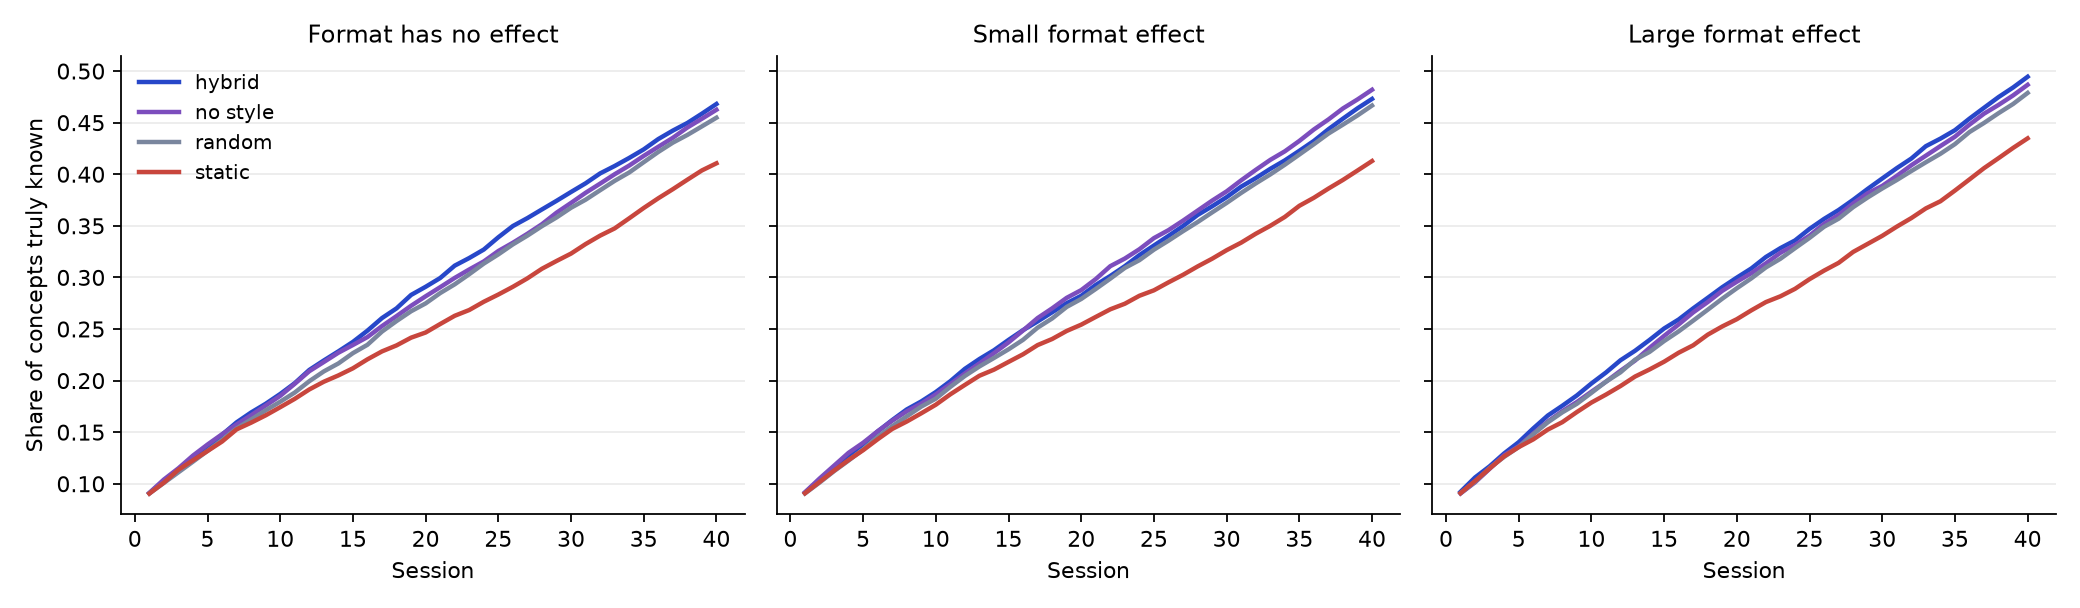

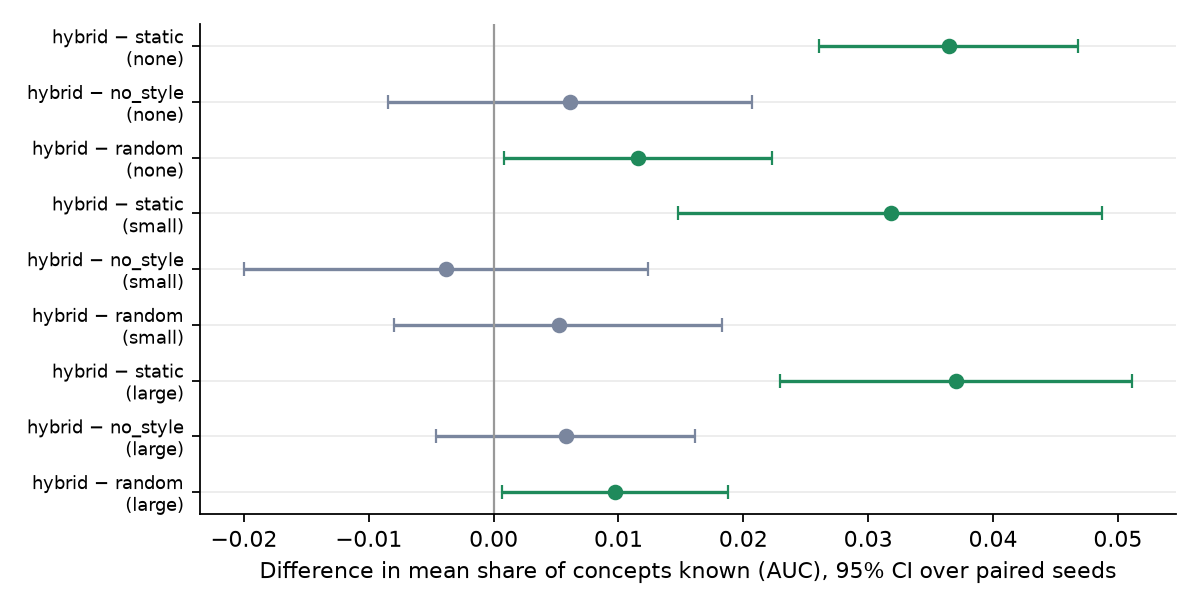

In [4]:
display(Image(OUT / 'figures' / 'sim_learning_curves.png'))
display(Image(OUT / 'figures' / 'sim_paired_differences.png'))

### Learning-preference recovery and the decisions taken

,style_case,start_style_cos,final_style_cos
0,noisy/with_update,0.8546,0.8260
1,noisy/prior_only,0.8695,0.8695
2,none/with_update,-0.0096,0.1051
3,none/prior_only,0.0000,0.0000
4,wrong/with_update,-0.9712,-0.8683
5,wrong/prior_only,-1.0000,-1.0000


Style update settings: {'lr': 1.0, 'prior_pull': 0.02, 'max_step': 0.2}
Weights: blueprint kept - adopt if mean validation gain >= 0.005 AUC and no affinity level loses > 0.005
Validation difference (tuned - blueprint): {'none': 0.0003, 'small': -0.0031, 'large': 0.0064}
Checks: {'hybrid_ge_static_every_level': True, 'hybrid_gt_static_when_style_matters': True, 'learned_style_beats_no_questionnaire': True, 'learned_style_recovers_from_wrong_questionnaire': True, 'aids_beat_checks_alone': True}


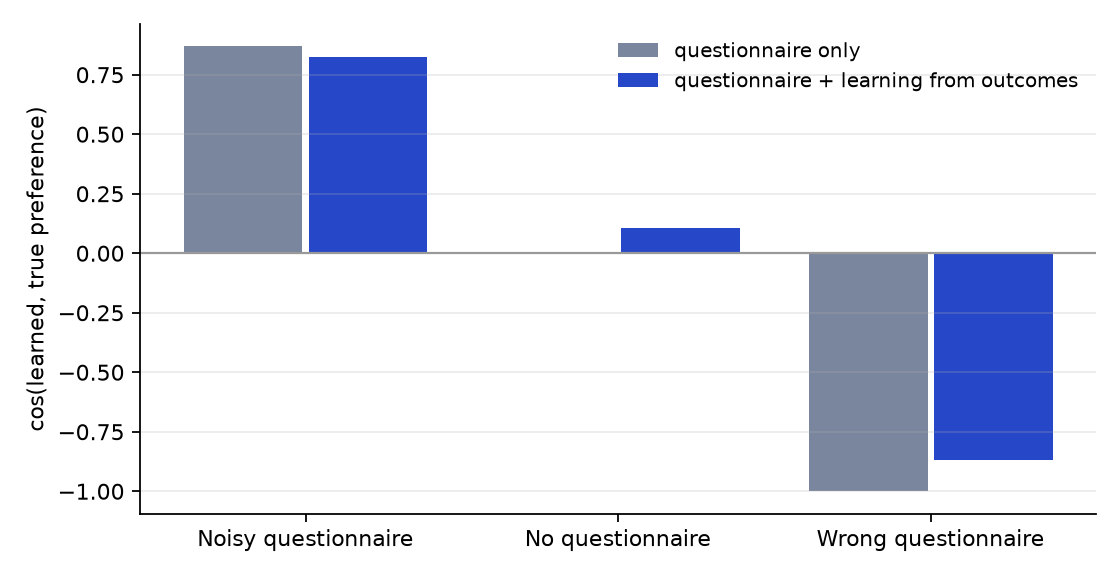

In [5]:
display(pd.DataFrame(sim['style_recovery'])[['style_case', 'start_style_cos', 'final_style_cos']])
print('Style update settings:', sim['style_tuning']['best'])
print('Weights:', 'tuned adopted' if sim['tuning']['adopted'] else 'blueprint kept', '-', sim['tuning']['rule'])
print('Validation difference (tuned - blueprint):', sim['tuning']['validation_diff_tuned_minus_v0'])
print('Checks:', sim['checks'])
display(Image(OUT / 'figures' / 'sim_style_recovery.png'))

## 2. Knowledge tracing on ASSISTments 2009

5-fold cross-validation by student, parameters fitted on training folds only, one-step-ahead predictions.

ASSISTments 2009 skill builder, 40 skills with the most students, 205546 answers. 5-fold cross-validation by student; parameters fitted on training folds only; one-step-ahead predictions. pyBKT is compared head to head on the largest skills (its EM is slow), with our BKT scored on exactly the same predictions.


,model,scope,auc,rmse,predictions
0,Global mean,40 skills,0.4901,0.4714,205546
1,Per-skill mean,40 skills,0.6040,0.4641,205546
2,"BKT, brute force (ours)",40 skills,0.7111,0.4381,205546
3,"BKT, brute force (ours)",10 largest skills,0.7001,0.4382,94350
4,"BKT, EM (pyBKT)",10 largest skills,0.7033,0.4376,94350


Median fitted parameters: {'prior': 0.7167, 'learn': 0.11, 'guess': 0.2192, 'slip': 0.1983}
Tripwires: {'bkt_auc_in_plausible_range_0.6_0.8': True, 'no_model_above_0.9': True, 'bkt_beats_per_skill_mean': True}


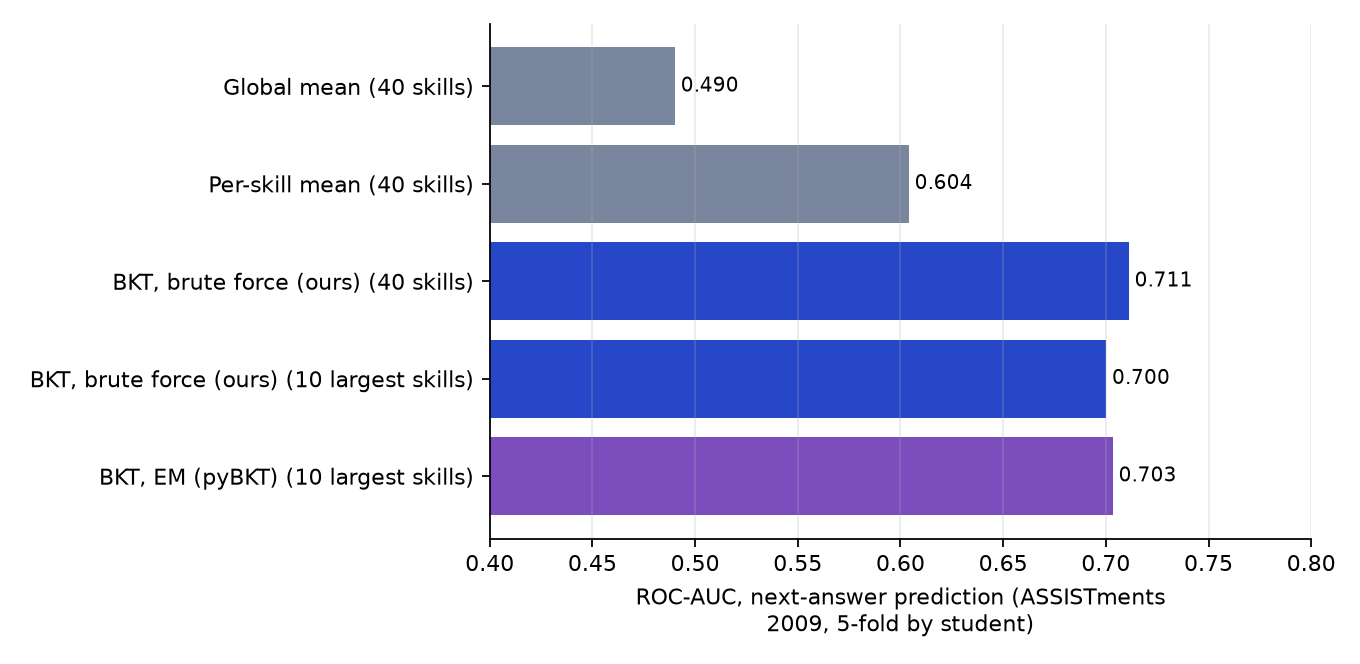

In [6]:
bkt = load('bkt_eval')
print(bkt['note'])
display(pd.DataFrame(bkt['table']))
print('Median fitted parameters:', bkt['median_params'])
print('Tripwires:', bkt['tripwires'])
display(Image(OUT / 'figures' / 'bkt_auc.png'))

## 3. OULAD

### At-risk after six weeks (train 2013, test 2014)

OULAD, features from the first 42 days only; trained on 2013 presentations (11620 students), tested on 2014 (15404 students). At-risk = Withdrawn or Fail (43% of the test set). Students who withdrew before day 42 are excluded.


,model,roc_auc,pr_auc,f1,recall_at_risk
0,Logistic regression,0.7284,0.7027,0.6365,0.7532
1,Random forest,0.7686,0.7478,0.6583,0.6852
2,Gradient boosting,0.7660,0.7365,0.6609,0.6962


Top features: {'mean_score': 0.179, 'clicks_last2w': 0.1252, 'active_days': 0.0794, 'clicks_total': 0.0782, 'clicks_homepage': 0.0773, 'clicks_content': 0.0772, 'clicks_forum': 0.0765, 'n_missing': 0.0644}


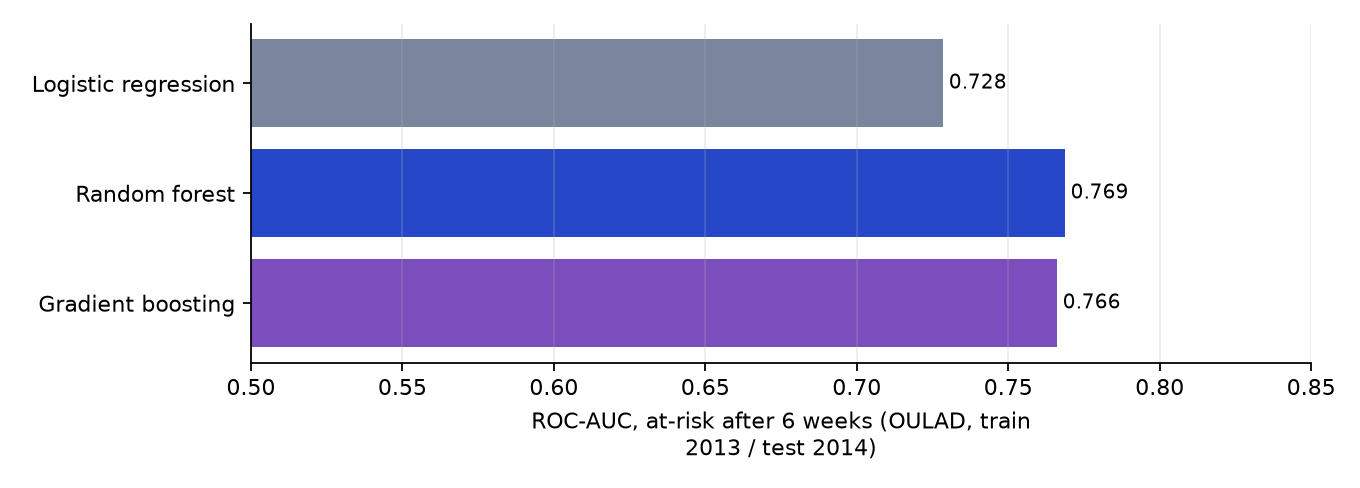

In [7]:
risk = load('risk')
print(risk['note'])
display(pd.DataFrame(risk['table']))
print('Top features:', risk['top_features_random_forest'])
display(Image(OUT / 'figures' / 'risk_roc_auc.png'))

### Engagement personas

In [8]:
per = load('personas')
print(per['note'])
display(pd.DataFrame(per['table']))
display(pd.DataFrame(per['clusters']))

OULAD 2014 presentations, 15521 students with at least 50 clicks; K-Means on standardised click shares, active days and log clicks.


,k,silhouette,stability_ari
0,3,0.2114,0.9871
1,4,0.2183,0.9731
2,5,0.2250,0.9795
3,6,0.2351,0.9871


,cluster,students,activity,leans_on,active_days_z
0,0,4484,low,content,-0.65
1,1,3325,high,content,0.92
2,2,1665,low,links,-0.45
3,3,116,low,other,-0.37
4,4,3289,medium,quiz,-0.38
5,5,2642,high,forum,0.72


### Collaborative filtering (per-student time split)

OULAD CCC 2014J: 2084 students, 220 course materials. Per-student time split (first 80% of materials opened = training, last 20% = target); training items excluded from candidates. This validates the CF methods on implicit clicks; the app's CF learns from outcome gain instead.


,model,precision_at_5,recall_at_5,ndcg_at_5,hit_rate_at_5,coverage
0,Random,0.0697,0.0291,0.0709,0.2812,0.9955
1,Most popular,0.2143,0.1554,0.2414,0.6204,0.3773
2,Item-kNN (ours),0.2584,0.1762,0.2965,0.7183,0.4318
3,"ALS (ours, implicit)",0.2313,0.1461,0.2464,0.6847,0.7273
4,LightFM hybrid (WARP + item type),0.2671,0.1701,0.2860,0.7817,0.7000


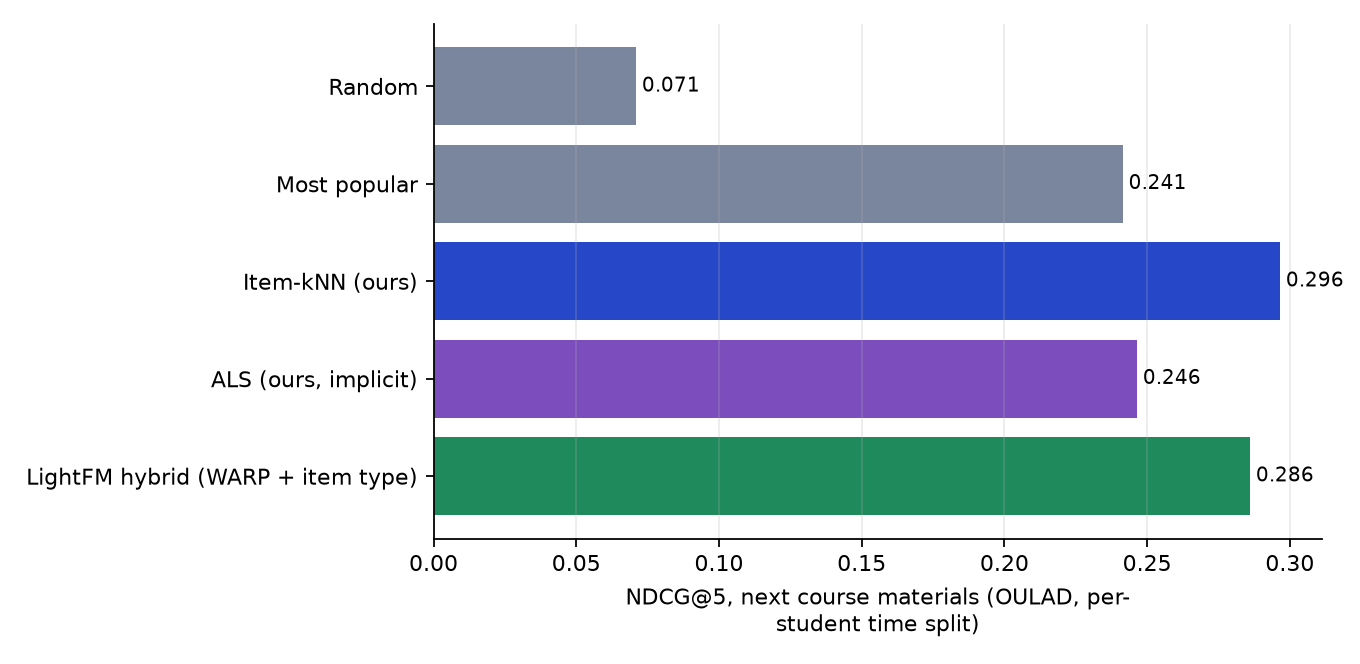

In [9]:
cf = load('cf_offline')
print(cf['note'])
display(pd.DataFrame(cf['table']))
display(Image(OUT / 'figures' / 'cf_ndcg.png'))

## 4. Pilot-study analysis

The pre-specified analysis (`research/src/pilot_analysis.py`) on simulated pilot data: it must detect a planted effect and must not detect one in null data. Run it on the real export after the pilot.

In [10]:
import sys

sys.path.insert(0, str(Path.cwd().parents[1]) if Path.cwd().name == 'notebooks' else '.')
from research.src.pilot_analysis import self_test  # noqa: E402

res = self_test()
pd.DataFrame([{'case': 'planted effect', **res['planted']}, {'case': 'no effect', **res['null']}])

,case,effect,ci95,p_value,r2
0,planted effect,0.1001,"[0.0179, 0.1822]",0.0183,0.4305
1,no effect,-0.0106,"[-0.1182, 0.097]",0.8431,0.1956
